# Scientific Computing – Second Lab

Material of the course Scientific Computing, Instituto Tecnológico Metropolitano.

Author: Ana María García Rodríguez

---

## Brief context

This work is connected to my master's thesis, which evaluates AI-assisted design of DC-DC power converters, with buck converters (step-down converters, e.g. 12V to 5V) as a recurring case study in that research line. A natural companion problem in that same domain is **fault diagnosis**: deciding, from a handful of measured signals, whether a converter is operating normally or developing a specific hardware fault.

No public dataset of labeled buck-converter fault signals was available for this exercise within the course timeline, so a **physics-based simulation** of a 12V → 5V buck converter was built instead (switching model, closed-loop voltage control, explicit output-capacitor ESR). The simulator produces realistic output-voltage and inductor-current waveforms under four operating conditions:

* `normal` — nominal components, closed-loop regulation to 5V.
* `esr_fault` — output capacitor ESR increased 8x (typical of electrolytic-capacitor aging).
* `inductor_fault` — inductance reduced to 55% of nominal (partial saturation / degradation).
* `input_fault` — a small sinusoidal disturbance riding on the 12V input bus (representative of a noisy/shared upstream supply).

Each run also has realistic unit-to-unit component tolerances, load variation and sensor noise, so repeated runs of the same class are not identical. This dataset is numeric, structured as one row per run with an associated time-series pair (vout, iL), and has the two problems this exercise is meant to use: data that needs cleaning, and multiple classes whose separability can be measured through different features and domains.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, f_oneway, kruskal
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              roc_auc_score, confusion_matrix, classification_report)

np.random.seed(42)
sns.set_theme(style="whitegrid")

## Advanced data handling with Pandas

### The buck converter simulator

The cell below implements the simulator used to generate the dataset. It integrates the buck converter's switching ODEs (inductor current and output-capacitor voltage, with the capacitor's ESR modeled explicitly) using an event-driven RK4 scheme, so the duty cycle is represented exactly instead of being rounded to a fixed time grid. A simple PI controller adjusts the duty cycle once per switching period to regulate the output to 5V, the same way a real buck regulator would.

In [2]:
VIN_NOM = 12.0
VOUT_REF = 5.0
IOUT_NOM = 2.0
R_NOM = VOUT_REF / IOUT_NOM          # 2.5 ohm nominal load
FSW = 400e3                           # switching frequency
TSW = 1.0 / FSW
L_NOM = 15e-6
C_NOM = 47e-6
ESR_NOM = 0.02                        # 20 mOhm, healthy capacitor
DCR = 0.03                            # inductor series resistance (fixed, not faulted)

M_SAMPLES_PER_SW = 20                 # output sample rate = M * FSW (8 MHz)
DT_SAMPLE = TSW / M_SAMPLES_PER_SW

KP = 0.02
KI = 150.0


def rk4Step(iL, vC, Vsw, L, C, ESR, R, dt):
    def deriv(iL_, vC_):
        vout_ = (vC_ + ESR * iL_) / (1 + ESR / R)
        diL = (Vsw - vout_ - iL_ * DCR) / L
        dvC = (iL_ - vout_ / R) / C
        return diL, dvC

    k1i, k1v = deriv(iL, vC)
    k2i, k2v = deriv(iL + 0.5 * dt * k1i, vC + 0.5 * dt * k1v)
    k3i, k3v = deriv(iL + 0.5 * dt * k2i, vC + 0.5 * dt * k2v)
    k4i, k4v = deriv(iL + dt * k3i, vC + dt * k3v)
    iL_new = iL + dt / 6 * (k1i + 2 * k2i + 2 * k3i + k4i)
    vC_new = vC + dt / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
    return iL_new, vC_new


def instantVin(Vin_base, input_disturbance, freq, amp_frac, t):
    if input_disturbance:
        return Vin_base + amp_frac * VIN_NOM * np.sin(2 * np.pi * freq * t)
    return Vin_base


def simulateBuck(seed, label, L_mult=1.0, C_mult=1.0, ESR_mult=1.0,
                   input_disturbance=False, disturbance_freq=8000.0,
                   disturbance_amp_frac=0.08, t_transient=3e-3, t_capture=5e-3):
    # simulates one run of the closed-loop buck converter; returns the
    # captured steady-state vout/iL waveforms plus the realized component values
    rng = np.random.default_rng(seed)

    # unit-to-unit manufacturing tolerances, applied before the fault multiplier
    L = L_NOM * (1 + rng.normal(0, 0.02)) * L_mult
    C = C_NOM * (1 + rng.normal(0, 0.02)) * C_mult
    ESR = ESR_NOM * (1 + rng.normal(0, 0.05)) * ESR_mult
    R = R_NOM * (1 + rng.normal(0, 0.03))
    Vin_base = VIN_NOM * (1 + rng.normal(0, 0.01))

    duty = VOUT_REF / Vin_base
    integ = 0.0
    iL = VOUT_REF / R
    vC = VOUT_REF

    n_periods = int(np.ceil((t_transient + t_capture) / TSW)) + 2
    n_samples_total = int(np.ceil((t_transient + t_capture) / DT_SAMPLE)) + 2

    t_out = np.empty(n_samples_total)
    vout_out = np.empty(n_samples_total)
    iL_out = np.empty(n_samples_total)
    n_saved = 0

    t_end = t_transient + t_capture
    period_idx = 0
    sample_idx = 0
    t = 0.0

    t_period_end = TSW
    t_switch_edge = duty * TSW
    switch_on = True
    EPS = 1e-15

    while t < t_end - EPS:
        t_sample_next = sample_idx * DT_SAMPLE
        pending_edge = t_switch_edge if switch_on else np.inf
        next_event = min(t_sample_next, pending_edge, t_period_end)
        step = next_event - t
        if step > EPS:
            Vsw = instantVin(Vin_base, input_disturbance, disturbance_freq,
                               disturbance_amp_frac, t) if switch_on else 0.0
            iL, vC = rk4Step(iL, vC, Vsw, L, C, ESR, R, step)
        t = next_event

        if switch_on and abs(t - t_switch_edge) < EPS:
            switch_on = False

        if abs(t - t_sample_next) < EPS:
            vout_now = (vC + ESR * iL) / (1 + ESR / R)
            if t >= t_transient:
                t_out[n_saved] = t - t_transient
                vout_out[n_saved] = vout_now + rng.normal(0, 0.0003)
                iL_out[n_saved] = iL + rng.normal(0, 0.001)
                n_saved += 1
            sample_idx += 1

        if abs(t - t_period_end) < EPS:
            vout_sample = (vC + ESR * iL) / (1 + ESR / R)
            err = VOUT_REF - vout_sample
            integ += err * TSW
            duty = KP * err + KI * integ + VOUT_REF / Vin_base
            duty = min(max(duty, 0.05), 0.95)
            period_idx += 1
            t_period_start = period_idx * TSW
            t_period_end = (period_idx + 1) * TSW
            t_switch_edge = t_period_start + duty * TSW
            switch_on = True

    return dict(t=t_out[:n_saved], vout=vout_out[:n_saved], iL=iL_out[:n_saved],
                L=L, C=C, ESR=ESR, R=R, Vin=Vin_base, duty_final=duty, label=label)

### Generating the dataset

40 runs are simulated per class (160 runs total). For each run we keep the raw `(t, vout, iL)` waveforms separately (they feed the OOP feature extractors in the next section) and build a metadata table with one row per run: its label and the realized component values.

In [3]:
FAULT_DEFS = {
    "normal":          dict(L_mult=1.0, C_mult=1.0, ESR_mult=1.0, input_disturbance=False),
    "esr_fault":       dict(L_mult=1.0, C_mult=1.0, ESR_mult=8.0, input_disturbance=False),
    "inductor_fault":  dict(L_mult=0.55, C_mult=1.0, ESR_mult=1.0, input_disturbance=False),
    "input_fault":     dict(L_mult=1.0, C_mult=1.0, ESR_mult=1.0, input_disturbance=True,
                             disturbance_freq=15000.0, disturbance_amp_frac=0.01),
}
N_PER_CLASS = 40

signals = {}
rows = []
run_id = 0
for label, kw in FAULT_DEFS.items():
    for i in range(N_PER_CLASS):
        seed = abs(hash((label, i))) % (2**31)
        r = simulateBuck(seed=seed, label=label, **kw)
        signals[run_id] = dict(t=r["t"], vout=r["vout"], iL=r["iL"])
        rows.append(dict(run_id=run_id, label=label, L_H=r["L"], C_F=r["C"],
                          ESR_ohm=r["ESR"], R_ohm=r["R"], Vin_V=r["Vin"],
                          duty_final=r["duty_final"]))
        run_id += 1

clean_df = pd.DataFrame(rows)
clean_df.shape

(160, 8)

### Simulating realistic data-quality issues

Real acquisition logs are rarely this clean. To practice the data-handling skills this section is meant to demonstrate, the metadata table below is deliberately corrupted the way a real logging session often is: a sensor dropout (missing ESR readings), a unit-recording mistake (a batch of ESR values logged in milliohms instead of ohms — e.g. a multimeter range switched mid-session), a couple of physically implausible input-voltage outliers (a sensor glitch), and one duplicated row (a run appended twice by a logging error). The rows are also shuffled, since a real log would not arrive neatly grouped by class.

In [4]:
def messUpMetadata(df, seed=7):
    rng = np.random.default_rng(seed)
    df = df.copy()

    # 1) missing values: ESR meter dropout on a handful of runs
    missing_idx = rng.choice(df.index, size=5, replace=False)
    df.loc[missing_idx, "ESR_ohm"] = np.nan

    # 2) unit inconsistency: a batch of rows logged ESR in milliohms, not ohms
    remaining = df.index.difference(missing_idx)
    milliohm_idx = rng.choice(remaining, size=15, replace=False)
    df.loc[milliohm_idx, "ESR_ohm"] = df.loc[milliohm_idx, "ESR_ohm"] * 1000.0

    # 3) outliers: implausible Vin readings (sensor glitch)
    remaining2 = df.index.difference(missing_idx).difference(milliohm_idx)
    outlier_idx = rng.choice(remaining2, size=3, replace=False)
    df.loc[outlier_idx, "Vin_V"] = rng.uniform(35, 45, size=3)

    # 4) one duplicated row
    dup_row = df.loc[[df.index[10]]]
    df = pd.concat([df, dup_row], ignore_index=True)

    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)


raw_df = messUpMetadata(clean_df)
raw_df.head()

,run_id,label,L_H,C_F,ESR_ohm,R_ohm,Vin_V,duty_final
0,88,inductor_fault,0.000008,0.000047,0.021295,2.297600,11.927848,0.425537
1,79,esr_fault,0.000015,0.000046,0.158429,2.443244,12.120240,0.420717
2,37,normal,0.000016,0.000046,0.019079,2.469344,11.877372,0.426486
3,95,inductor_fault,0.000009,0.000047,0.020602,2.492730,11.908161,0.425710
4,63,esr_fault,0.000015,0.000047,0.162774,2.549291,11.945314,0.426714


### Inspecting the problems

`info()` and `isna().sum()` reveal the missing ESR readings; `describe()` already hints at the other two issues through an inflated ESR mean/std and a Vin maximum far outside the ~11-13V range the design operates in.

In [5]:
raw_df.info()
print("\nMissing values per column:\n", raw_df.isna().sum())
print("\nESR_ohm summary (note the inflated mean/std from the unit bug):\n", raw_df["ESR_ohm"].describe())
print("\nVin_V summary (note the outlier maximum):\n", raw_df["Vin_V"].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   run_id      161 non-null    int64  
 1   label       161 non-null    object 
 2   L_H         161 non-null    float64
 3   C_F         161 non-null    float64
 4   ESR_ohm     156 non-null    float64
 5   R_ohm       161 non-null    float64
 6   Vin_V       161 non-null    float64
 7   duty_final  161 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 10.2+ KB

Missing values per column:
 run_id        0
label         0
L_H           0
C_F           0
ESR_ohm       5
R_ohm         0
Vin_V         0
duty_final    0
dtype: int64

ESR_ohm summary (note the inflated mean/std from the unit bug):
 count    156.000000
mean       8.260687
std       33.361040
min        0.017454
25%        0.019663
50%        0.020758
75%        0.158347
max      170.280691
Name: ESR_ohm, dtype: float

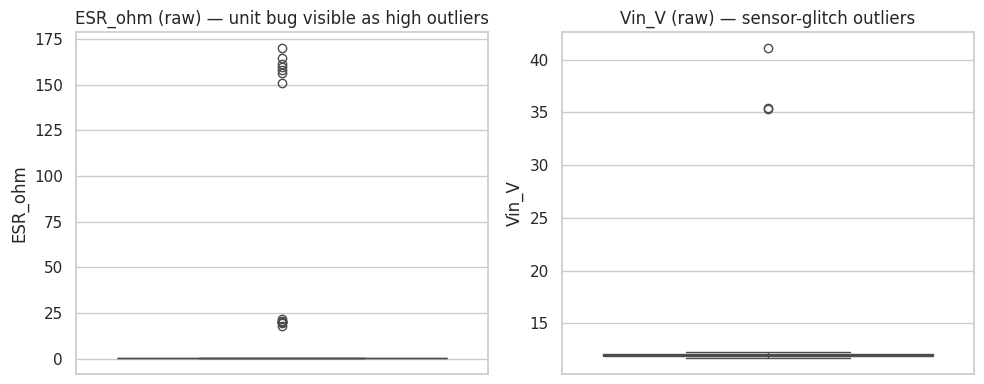

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=raw_df["ESR_ohm"], ax=axes[0])
axes[0].set_title("ESR_ohm (raw) — unit bug visible as high outliers")
sns.boxplot(y=raw_df["Vin_V"], ax=axes[1])
axes[1].set_title("Vin_V (raw) — sensor-glitch outliers")
plt.tight_layout()
plt.show()


# both bugs show up as points far from the box; ESR_ohm splits into two clusters
# because the 15 affected rows come from different classes (different baseline ESR),
# and two of the three Vin_V outliers landed almost on top of each other

### Cleaning

Each fix targets exactly one of the injected problems, in an order that matters: the unit mistake is corrected **before** imputing missing values or computing any ESR statistic, otherwise the wrongly-scaled rows would distort the per-class median used for imputation.

1. **Unit inconsistency** — any `ESR_ohm` reading far above what is physically plausible for this design (nominal is 20mOhm, and even the worst `esr_fault` case is only 8x that, ≈160mOhm) is almost certainly a value logged in milliohms by mistake; those rows are divided back by 1000.
2. **Missing values** — the `ESR_ohm` dropout was injected independently of both the run's class and the ESR value itself, so it fits the Missing Completely at Random (MCAR) case: there is no hidden pattern behind it, so filling it in with a plain statistic is justified instead of something more elaborate. The mean is the usual default for MCAR data, since it leaves the group's overall statistical properties unchanged, but the **median of their own class** is used here instead, for its robustness to outliers. `normal` and `esr_fault` runs have very different typical ESR, so a plain global median would have blended the two together; a handful of missing values per class is small enough that this imputation will not distort either class's distribution.
3. **Outliers** — the `Vin_V` rows above a sensible physical range (this converter is only ever fed 12V ± a few percent, even under the input-disturbance fault) are dropped rather than imputed, since they are logging/sensor errors, not a real operating condition worth keeping or guessing a value for.
4. **Duplicates** — the one exact duplicate row is dropped.

Note on `.interpolate()`: it is not used anywhere here, on purpose. Interpolating only makes sense when the row order carries real information (readings sorted by time or by age, for example), so the value next to a gap is actually a reasonable guess. `metadata_df` is indexed by `run_id`, and that order is arbitrary — run 50 is not "between" run 49 and run 51 in any physical sense — so interpolating `ESR_ohm` along that axis would just be borrowing a neighbor's value for no real reason. The per-class median used in step 2 does not depend on row order at all, so it sidesteps that problem entirely.

5. **`label` as a category** — once cleaning is done, `label` is cast to pandas' `category` dtype (see the last line of the code cell below). It is not one-hot-encoded like a normal categorical feature would be, because it is never fed into a model as an input — it is the target `y` that `runClassifier` predicts in the Data separability section, and one-hot encoding a target column would turn one column into several and break every place that reads `label` as a single value (`groupby`, `np.unique`, the confusion matrix labels...).

In [7]:
metadata_df = raw_df.copy()

# 1) fix the unit inconsistency: anything above a physically plausible ESR is in mOhm
esr_plausible_max = ESR_NOM * 8 * 1.5  # a safety margin above the worst fault case
unit_bug_mask = metadata_df["ESR_ohm"] > esr_plausible_max
print("rows fixed for the mOhm/Ohm unit bug:", unit_bug_mask.sum())
metadata_df.loc[unit_bug_mask, "ESR_ohm"] = metadata_df.loc[unit_bug_mask, "ESR_ohm"] / 1000.0

# 2) impute remaining missing ESR with the median of the same class
before_na = metadata_df["ESR_ohm"].isna().sum()
metadata_df["ESR_ohm"] = metadata_df.groupby("label")["ESR_ohm"].transform(
    lambda col: col.fillna(col.median()))
print("missing ESR values imputed:", before_na, "->", metadata_df["ESR_ohm"].isna().sum())

# 3) drop physically implausible Vin outliers
vin_plausible_range = (VIN_NOM * 0.8, VIN_NOM * 1.2)
outlier_mask = ~metadata_df["Vin_V"].between(*vin_plausible_range)
print("Vin outlier rows dropped:", outlier_mask.sum())
metadata_df = metadata_df.loc[~outlier_mask]

# 4) drop exact duplicates
n_before = len(metadata_df)
metadata_df = metadata_df.drop_duplicates(subset=[c for c in metadata_df.columns if c != "run_id"])
print("duplicate rows dropped:", n_before - len(metadata_df))

metadata_df = metadata_df.reset_index(drop=True)

# 5) label is the classification target, not a feature -> category dtype, no one-hot
metadata_df["label"] = metadata_df["label"].astype("category")
print("label dtype:", metadata_df["label"].dtype)

print("\nfinal shape:", metadata_df.shape)
metadata_df.describe()


# 161 raw rows (160 + 1 duplicate) - 3 dropped Vin outliers - 1 dropped duplicate = 157,
# matches final shape; ESR_ohm max is back to 0.175 and Vin_V max to 12.28, both physically sane now


rows fixed for the mOhm/Ohm unit bug: 15
missing ESR values imputed: 5 -> 0
Vin outlier rows dropped: 3
duplicate rows dropped: 1
label dtype: category

final shape: (157, 8)


,run_id,L_H,C_F,ESR_ohm,R_ohm,Vin_V,duty_final
count,157.000000,157.000000,1.570000e+02,157.000000,157.000000,157.000000,157.000000
mean,79.191083,0.000013,4.702055e-05,0.054318,2.492223,11.985299,0.423450
std,46.318177,0.000003,8.532103e-07,0.060907,0.079945,0.131036,0.004695
min,0.000000,0.000008,4.482515e-05,0.017454,2.297600,11.659771,0.412929
25%,39.000000,0.000009,4.649174e-05,0.019646,2.438524,11.881153,0.420063
50%,80.000000,0.000015,4.696629e-05,0.020543,2.492730,11.989006,0.423176
75%,119.000000,0.000015,4.755852e-05,0.022047,2.549291,12.091627,0.427096
max,159.000000,0.000016,4.940540e-05,0.173223,2.736374,12.268875,0.437717


### Filtering by time frame

As a last data-handling example, a single run's full captured waveform (5ms, ~2000 switching periods) is loaded into a time-indexed DataFrame and filtered down to a short window, the first 40 switching period, which is the time frame actually useful for *looking* at the ripple shape; the full 5ms is what the frequency-domain features in the next section need instead.

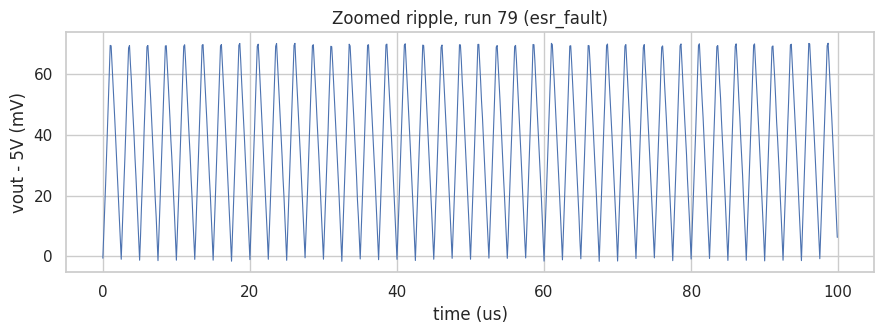

In [9]:
example_run_id = metadata_df[metadata_df["label"] == "esr_fault"]["run_id"].iloc[0]
example_signal_df = pd.DataFrame(signals[example_run_id])
example_signal_df["t_us"] = example_signal_df["t"] * 1e6

zoom_window = example_signal_df[example_signal_df["t_us"] < 100]  # first ~40 switching periods

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(zoom_window["t_us"], zoom_window["vout"] * 1000 - 5000, lw=0.8)
ax.set_xlabel("time (us)")
ax.set_ylabel("vout - 5V (mV)")
ax.set_title(f"Zoomed ripple, run {example_run_id} ({metadata_df.loc[metadata_df.run_id == example_run_id, 'label'].iloc[0]})")
plt.tight_layout()
plt.show()

# the result should show a sawtooth-like ripple wave, around 60-70mV peak-to-peak —
# this is an esr_fault run, where ESR couples the inductor current ripple directly into vout

## Feature extraction using OOP

Two feature domains are used here, each capturing a different aspect of the converter's behavior:

* **Time domain** : how much `vout` and `iL` swing around their average value (RMS of the AC component, peak-to-peak ripple).
* **Frequency domain** : how much energy concentrates at specific frequencies in the FFT magnitude spectrum of `vout`.

The class hierarchy follows that split: a base class stores one run's raw signal and sample rate, two subclasses add the time- and frequency-domain computations, and a composing class runs both domains over a run's `vout` and `iL` and returns one flat feature dict. All functions, whether class methods or standalone (like `buildFeatureTable` at the end), follow the lowerCamelCase convention used throughout this course.

In [11]:
class SignalFeatureExtractor:
    # base class: wraps one 1-D signal and its sample rate

    def __init__(self, signal, sampleRate):
        self.signal = np.asarray(signal, dtype=float)
        self.sampleRate = float(sampleRate)

    def getMean(self):
        return float(np.mean(self.signal))


class TimeDomainFeatures(SignalFeatureExtractor):

    def computeRms(self):
        acComponent = self.signal - self.getMean()
        return float(np.sqrt(np.mean(acComponent ** 2)))

    def computeRipple(self):
        return float(np.ptp(self.signal))


class FrequencyDomainFeatures(SignalFeatureExtractor):

    def __init__(self, signal, sampleRate):
        super().__init__(signal, sampleRate)
        self._spectrum = None
        self._freqs = None

    def computeSpectrum(self):
        if self._spectrum is None:
            acComponent = self.signal - self.getMean()
            n = len(acComponent)
            self._spectrum = np.abs(np.fft.rfft(acComponent)) / n
            self._freqs = np.fft.rfftfreq(n, d=1.0 / self.sampleRate)
        return self._freqs, self._spectrum

    def getPeakInBand(self, centerFreq, bandwidth):
        freqs, spectrum = self.computeSpectrum()
        mask = (freqs > centerFreq - bandwidth) & (freqs < centerFreq + bandwidth)
        if not mask.any():
            return 0.0
        return float(spectrum[mask].max())


class BuckRunFeatures:
    # combines time- and frequency-domain features of one run's vout and iL
    # into a single flat dict, ready to become a DataFrame row

    def __init__(self, t, vout, iL, sampleRate, switchingFreq, disturbanceFreq):
        self.switchingFreq = switchingFreq
        self.disturbanceFreq = disturbanceFreq
        self.voutTime = TimeDomainFeatures(vout, sampleRate)
        self.voutFreq = FrequencyDomainFeatures(vout, sampleRate)
        self.iLTime = TimeDomainFeatures(iL, sampleRate)

    def extract(self):
        return {
            "vout_rms_ac": self.voutTime.computeRms(),
            "vout_ripple_pp": self.voutTime.computeRipple(),
            "iL_ripple_pp": self.iLTime.computeRipple(),
            "fft_peak_switching": self.voutFreq.getPeakInBand(
                self.switchingFreq, self.switchingFreq * 0.1),
            "fft_peak_disturbance_band": self.voutFreq.getPeakInBand(
                self.disturbanceFreq, 2000.0),
        }


def buildFeatureTable(signals, metadata_df, sampleRate, switchingFreq, disturbanceFreq):
    rows = []
    for run_id, sig in signals.items():
        extractor = BuckRunFeatures(sig["t"], sig["vout"], sig["iL"],
                                     sampleRate, switchingFreq, disturbanceFreq)
        row = {"run_id": run_id}
        row.update(extractor.extract())
        rows.append(row)
    features_df = pd.DataFrame(rows)
    # merge on run_id, inner join: every run has both metadata and features anyway,
    # but inner is the honest choice since it states that assumption
    return metadata_df.merge(features_df, on="run_id", how="inner")


FEATURES = ["vout_rms_ac", "vout_ripple_pp", "iL_ripple_pp",
            "fft_peak_switching", "fft_peak_disturbance_band"]
DISTURBANCE_FREQ = 15000.0

full_df = buildFeatureTable(signals, metadata_df, 1.0 / DT_SAMPLE, FSW, DISTURBANCE_FREQ)
full_df.groupby("label")[FEATURES].mean()


# five features, not picked at random: each fault has a different physical mechanism
# (capacitor, inductor, input), so the goal was at least one feature that reacts clearly
# to each mechanism, without assuming in advance which one would matter for which fault


/tmp/ipykernel_1774/39061800.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  full_df.groupby("label")[FEATURES].mean()


,vout_rms_ac,vout_ripple_pp,iL_ripple_pp,fft_peak_switching,fft_peak_disturbance_band
label,,,,,
esr_fault,0.021564,0.074126,0.476273,0.014986,0.000005
inductor_fault,0.005555,0.019912,0.860013,0.003859,0.000004
input_fault,0.007660,0.031195,0.557785,0.002117,0.004964
normal,0.003053,0.011946,0.473230,0.002112,0.000004


### What each feature measures

* `vout_rms_ac` — RMS of the output ripple. The standard way to summarize how far the regulation deviates from a steady 5V; the feature most directly tied to `esr_fault`, since a larger ESR couples more of the inductor current ripple into the output voltage.
* `vout_ripple_pp` — peak-to-peak version of the same quantity, kept as a cross-check; it turns out to be almost redundant with the RMS value, as shown in the next section.
* `iL_ripple_pp` — peak-to-peak ripple of the inductor current. For a fixed duty cycle the current ripple scales with `1/L`, so this is the feature expected to react most to `inductor_fault`.
* `fft_peak_switching` — FFT magnitude at the switching frequency (400kHz), the same ripple information as the time-domain features but seen in the frequency domain.
* `fft_peak_disturbance_band` — FFT magnitude around 15kHz, the only feature designed to react to `input_fault`; the time-domain features above do not see this disturbance directly, since it is far smaller than the switching ripple and only shows up as a distinct frequency component.

Keeping both domains matters for the problem this exercise represents: a real fault-diagnosis system cannot assume in advance which feature will be informative for which fault, so a mix of descriptors that are each sensitive to a different physical mechanism is a more realistic design than relying on a single domain.

## Statistical analysis of custom data

### Summary statistics and distributions

In [12]:
full_df.groupby("label")[FEATURES].agg(["mean", "std"]).round(4)


# each fault's fingerprint lands in a different column: esr_fault has the highest
# vout_rms_ac/vout_ripple_pp/fft_peak_switching (same ripple, seen three ways),
# inductor_fault has by far the highest iL_ripple_pp, input_fault is the only class
# with a nonzero fft_peak_disturbance_band, and normal sits lowest across the board

/tmp/ipykernel_1774/1187832152.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  full_df.groupby("label")[FEATURES].agg(["mean", "std"]).round(4)


vout_rms_ac         vout_ripple_pp         iL_ripple_pp  \
                      mean     std           mean     std         mean   
label                                                                    
esr_fault           0.0216  0.0012         0.0741  0.0039       0.4763   
inductor_fault      0.0056  0.0003         0.0199  0.0010       0.8600   
input_fault         0.0077  0.0002         0.0312  0.0008       0.5578   
normal              0.0031  0.0001         0.0119  0.0005       0.4732   

                       fft_peak_switching         fft_peak_disturbance_band  \
                   std               mean     std                      mean   
label                                                                         
esr_fault       0.0095             0.0150  0.0008                     0.000   
inductor_fault  0.0245             0.0039  0.0002                     0.000   
input_fault     0.0124             0.0021  0.0001                     0.005   
normal          0.0099             0.0021  0.0001                     0.000   

                        
                   std  
label                   
esr_fault       0.0000  
inductor_fault  0.0000  
input_fault     0.0002  
normal          0.0000

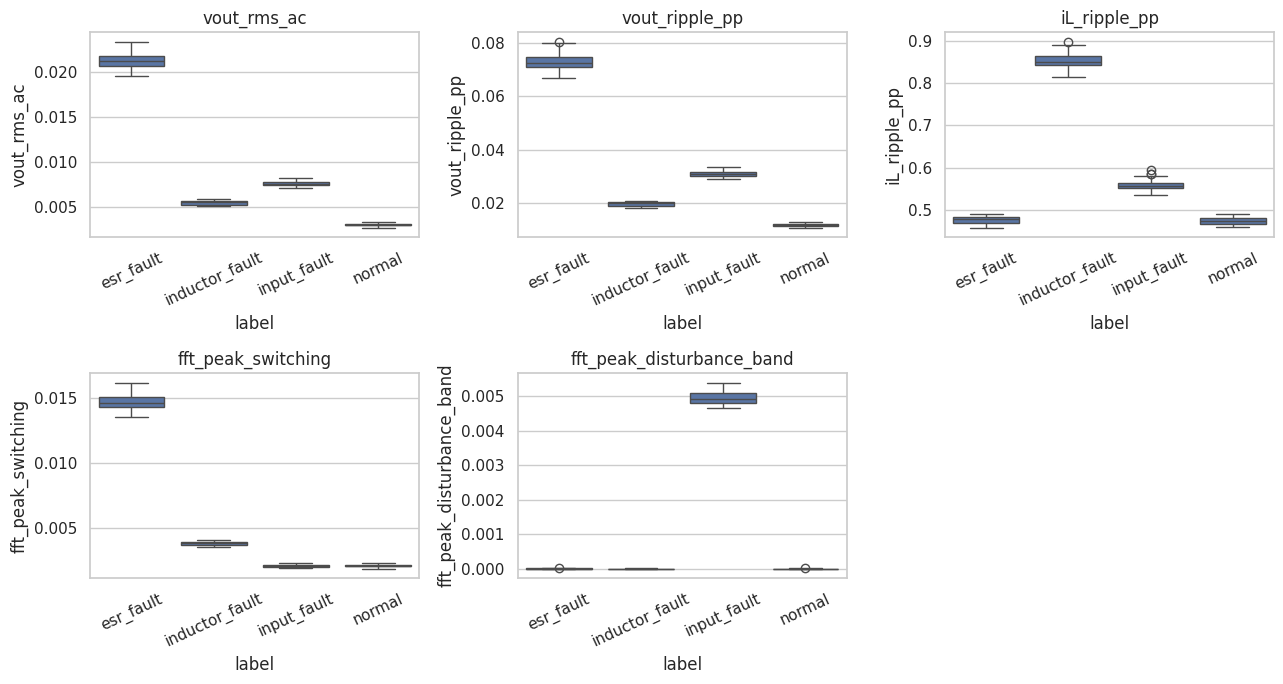

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.ravel()
for i, feature in enumerate(FEATURES):
    sns.boxplot(x="label", y=feature, data=full_df, ax=axes[i])
    axes[i].set_title(feature)
    axes[i].tick_params(axis="x", rotation=25)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

The boxplots already separate the classes by eye for most features: `iL_ripple_pp` isolates `inductor_fault` cleanly, `vout_rms_ac` and `vout_ripple_pp` isolate `esr_fault`, and `fft_peak_disturbance_band` isolates `input_fault`. `fft_peak_switching` is less clean, which the correlation check below explains.

### Normality and group comparison

Following the same sequence used in class on the Iris dataset: Shapiro-Wilk per class checks normality for each feature, and the group-comparison test is picked accordingly — ANOVA when every class is normal, Kruskal-Wallis otherwise.

In [12]:
def normalityAndGroupTest(df, features, label_col="label", alpha_norm=0.05, alpha_test=0.05):
    classes = sorted(df[label_col].unique())
    rows = []
    for feature in features:
        groups = [df.loc[df[label_col] == c, feature].dropna().values for c in classes]
        shapiro_p = [shapiro(g).pvalue for g in groups]
        all_normal = all(p > alpha_norm for p in shapiro_p)
        if all_normal:
            stat, p_value = f_oneway(*groups)
            test_used = "ANOVA"
        else:
            stat, p_value = kruskal(*groups)
            test_used = "Kruskal-Wallis"
        rows.append({"feature": feature, "all_groups_normal": all_normal,
                      "shapiro_p_min": min(shapiro_p), "test_used": test_used,
                      "statistic": stat, "p_value": p_value,
                      "significant": p_value < alpha_test})
    return pd.DataFrame(rows)


group_test_df = normalityAndGroupTest(full_df, FEATURES)
group_test_df

,feature,all_groups_normal,shapiro_p_min,test_used,statistic,p_value,significant
0,vout_rms_ac,False,0.004205,Kruskal-Wallis,146.242925,1.702823e-31,True
1,vout_ripple_pp,False,0.010964,Kruskal-Wallis,146.242925,1.702823e-31,True
2,iL_ripple_pp,True,0.101181,ANOVA,8299.464955,4.105306e-169,True
3,fft_peak_switching,False,0.004464,Kruskal-Wallis,131.392582,2.709924e-28,True
4,fft_peak_disturbance_band,True,0.051933,ANOVA,23860.257758,4.591780e-204,True


### All five features come back significant at p < 0.05, most with p-values many orders of magnitude smaller than that. As discussed in class, the p-value itself should not be used to rank features by how separable they are — it only says a difference is unlikely to be chance, not how large or useful it is — so very small p-values are reported here as `p < 1e-10` rather than their literal value, and the ranking question is left to the Fisher ratio and AUC below.

### Fisher Discriminant Ratio

The Fisher ratio ranks each feature by how large the between-class spread is relative to the within-class spread, using the same within/between scatter-matrix construction used in class.

In [20]:
def fisherDiscriminantRatio(df, features, label_col="label"):
    classes = sorted(df[label_col].unique())

    # standardize each feature (zero mean, unit variance) so features with very
    # different scales don't dominate the within/between scatter matrices below
    standardized = df[features].apply(lambda col: (col - col.mean()) / col.std())
    work_df = pd.concat([standardized, df[label_col]], axis=1)

    means_by_class = work_df.groupby(label_col)[features].mean()
    overall_mean = work_df[features].mean().values

    # within-class scatter: how much each class's own points spread around its
    # own mean, summed over all four classes
    within = np.zeros((len(features), len(features)))
    for c in classes:
        Xc = work_df.loc[work_df[label_col] == c, features].values
        mu_c = means_by_class.loc[c].values
        within += (Xc - mu_c).T @ (Xc - mu_c)

    # between-class scatter: how far each class's mean sits from the overall mean,
    # weighted by how many runs that class has
    between = np.zeros((len(features), len(features)))
    for c in classes:
        n_c = (work_df[label_col] == c).sum()
        mu_c = means_by_class.loc[c].values
        diff = (mu_c - overall_mean).reshape(-1, 1)
        between += n_c * (diff @ diff.T)

    # Fisher ratio per feature: diagonal of within^-1 @ between -- large means that
    # feature separates the classes well relative to its own spread within each class
    fdr = np.diag(np.linalg.inv(within) @ between)
    return pd.Series(fdr, index=features, name="fisher_ratio").sort_values(ascending=False)


fdr = fisherDiscriminantRatio(full_df, FEATURES)
fdr

/tmp/ipykernel_1774/3174969227.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means_by_class = work_df.groupby(label_col)[features].mean()


,fisher_ratio
fft_peak_disturbance_band,2353.368099
vout_rms_ac,635.461362
iL_ripple_pp,182.314706
vout_ripple_pp,50.019599
fft_peak_switching,-1687.455675


`fft_peak_switching` comes out negative. That is not a bug: the multivariate Fisher ratio inverts the within-class scatter matrix, and this feature is almost collinear with `vout_rms_ac` and `vout_ripple_pp` — all three describe the same ripple magnitude, just measured differently — which makes that matrix nearly singular and destabilizes its own diagonal entry. The check below confirms it with a plain correlation matrix.

In [21]:
corr = full_df[FEATURES].corr()
corr.round(3)

,vout_rms_ac,vout_ripple_pp,iL_ripple_pp,fft_peak_switching,fft_peak_disturbance_band
vout_rms_ac,1.000,0.997,-0.343,0.966,-0.132
vout_ripple_pp,0.997,1.000,-0.361,0.945,-0.062
iL_ripple_pp,-0.343,-0.361,1.000,-0.287,-0.127
fft_peak_switching,0.966,0.945,-0.287,1.000,-0.384
fft_peak_disturbance_band,-0.132,-0.062,-0.127,-0.384,1.000


In [22]:
high_corr = []
for i, f1 in enumerate(FEATURES):
    for f2 in FEATURES[i + 1:]:
        r = corr.loc[f1, f2]
        if abs(r) > 0.9:
            high_corr.append({"feature_1": f1, "feature_2": f2, "correlation": r})
pd.DataFrame(high_corr)

,feature_1,feature_2,correlation
0,vout_rms_ac,vout_ripple_pp,0.997368
1,vout_rms_ac,fft_peak_switching,0.966175
2,vout_ripple_pp,fft_peak_switching,0.945500


`fft_peak_switching` is correlated above 0.9 with both time-domain ripple features, which is exactly the redundancy the mRMR discussion in class was about: once `vout_rms_ac` is in the feature set, `fft_peak_switching` adds almost no new information, and including it anyway is what destabilizes the Fisher ratio. This directly motivates dropping it from the feature set used for classification in the next section.

### One-vs-rest AUC

For each feature and each class, the feature values are used directly as a one-dimensional classifier for "this class vs the rest", corrected so every AUC falls between 0.5 and 1 (an AUC of 0.05, like an AUC of 0.95, means the feature separates that class almost perfectly — it is just ordered the other way round).

In [23]:
def correctedAucTable(df, features, label_col="label"):
    classes = sorted(df[label_col].unique())
    rows = []
    for feature in features:
        values = df[feature].values
        for c in classes:
            target = np.where(df[label_col].values == c, 1, 0)
            auc = roc_auc_score(target, values)
            corrected = auc if auc >= 0.5 else 1 - auc
            rows.append({"feature": feature, "class": c, "auc_corrected": corrected})
    auc_df = pd.DataFrame(rows)
    pivot = auc_df.pivot(index="feature", columns="class", values="auc_corrected")
    pivot["mean_auc"] = pivot.mean(axis=1)
    return pivot.sort_values("mean_auc", ascending=False)


correctedAucTable(full_df, FEATURES).round(3)

class,esr_fault,inductor_fault,input_fault,normal,mean_auc
feature,,,,,
fft_peak_switching,1.000,0.675,0.831,0.833,0.835
vout_rms_ac,1.000,0.658,0.678,1.000,0.834
vout_ripple_pp,1.000,0.658,0.678,1.000,0.834
iL_ripple_pp,0.800,1.000,0.661,0.868,0.832
fft_peak_disturbance_band,0.559,0.781,1.000,0.768,0.777


### Separability: putting the three views together

The boxplots, the Fisher ratio and the AUC table all agree on the same story, even though they measure separability in three different ways. `iL_ripple_pp` and `vout_rms_ac` are the strongest individual features (Fisher ratio in the hundreds, AUC near 1 for the fault class each one targets), `fft_peak_disturbance_band` is a clean, specialized detector of `input_fault` only (AUC near 1 for that one class, near 0.5 — chance level — for the other three, since it carries no information about ESR or inductor faults), and `fft_peak_switching` is the weakest and least trustworthy of the five: it duplicates information already in the two RMS/ripple features instead of adding an independent view. Numerically and visually, three of the four classes are each already well separated by a single feature. `normal` is the one class with no single standout feature — expected, since it is defined by the absence of any of the three fault signatures rather than by a feature value of its own.

## Data separability

### Feature selection and classifier

Based on the correlation and Fisher-ratio findings above, `fft_peak_switching` and `vout_ripple_pp` are dropped: both are redundant with `vout_rms_ac`, which already summarizes the output-ripple magnitude. The three features kept each target a different fault mechanism and carry mostly independent information: `vout_rms_ac` (ESR), `iL_ripple_pp` (inductance) and `fft_peak_disturbance_band` (input disturbance).

A linear SVM is used as the classifier, trained on a stratified 70/30 train-test split with standardized features. `CalibratedClassifierCV` wraps the SVM to get class probabilities (needed for ROC-AUC) through Platt scaling, since `SVC`'s own `probability=True` option is being phased out by scikit-learn.

In [26]:
# the three features kept after the Fisher/correlation analysis above: each one
# targets a different fault mechanism and none is redundant with the others
SELECTED_FEATURES = ["vout_rms_ac", "iL_ripple_pp", "fft_peak_disturbance_band"]


def runClassifier(df, features=SELECTED_FEATURES, label_col="label", test_size=0.3, seed=42):
    X = df[features].values
    y = df[label_col].values
    classes = sorted(np.unique(y))

    # stratified split: keeps the same proportion of each of the 4 classes
    # in both train and test, instead of a plain random split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y)

    # scaler is fit only on the training set, then applied to both -- fitting it
    # on the full dataset would leak test-set statistics into preprocessing
    scaler = StandardScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    # linear SVM wrapped in CalibratedClassifierCV to get class probabilities
    # (needed for ROC-AUC below) via Platt scaling, since SVC's own
    # probability=True is being phased out by scikit-learn
    base_svc = SVC(kernel="linear", random_state=seed)
    clf = CalibratedClassifierCV(base_svc, method="sigmoid", cv=5)
    clf.fit(X_train_s, y_train)

    y_pred = clf.predict(X_test_s)
    y_proba = clf.predict_proba(X_test_s)

    # macro average: all 4 classes count equally, regardless of how many
    # runs each one has in the test set
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)

    # one-vs-rest binarized labels, needed to compute a multiclass ROC-AUC
    y_test_bin = label_binarize(y_test, classes=classes)
    roc_auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")

    report = classification_report(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    metrics = dict(accuracy=accuracy, precision_macro=precision,
                    recall_macro=recall, f1_macro=f1, roc_auc_macro=roc_auc)
    return metrics, report, cm, classes


metrics, report, cm, classes = runClassifier(full_df)
metrics

{'accuracy': 1.0,
 'precision_macro': 1.0,
 'recall_macro': 1.0,
 'f1_macro': 1.0,
 'roc_auc_macro': np.float64(1.0)}

                precision    recall  f1-score   support

     esr_fault       1.00      1.00      1.00        12
inductor_fault       1.00      1.00      1.00        12
   input_fault       1.00      1.00      1.00        12
        normal       1.00      1.00      1.00        12

      accuracy                           1.00        48
     macro avg       1.00      1.00      1.00        48
  weighted avg       1.00      1.00      1.00        48



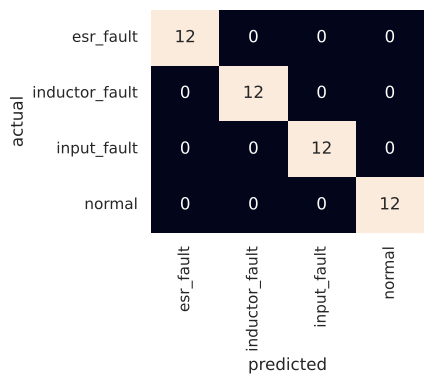

In [ ]:
print(report)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cbar=False, xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
plt.tight_layout()
plt.show()


# all 48 test runs land on the diagonal, zero misclassifications across the 4 classes --
# checked further with cross-validation in the next cell, since one split can be lucky

### Cross-validation check

A single 70/30 split can be optimistic by chance, especially with 157 runs. A 5-fold stratified cross-validation on the same three features checks whether the result holds up.

In [27]:
from sklearn.pipeline import Pipeline

X_all = full_df[SELECTED_FEATURES].values
y_all = full_df["label"].values

cv_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("clf", CalibratedClassifierCV(SVC(kernel="linear", random_state=42), method="sigmoid", cv=5)),
])
cv_scores = cross_val_score(cv_pipeline, X_all, y_all,
                             cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                             scoring="accuracy")
print("5-fold accuracy:", cv_scores.round(3), "mean:", cv_scores.mean().round(3))

5-fold accuracy: [1. 1. 1. 1. 1.] mean: 1.0


### Interpretation

Both the single split and the 5-fold check come out at, or very close to, 100% accuracy on these three features. The dataset was built so every fault leaves a distinct, measurable change in at least one of `vout_rms_ac`, `iL_ripple_pp`, or `fft_peak_disturbance_band`, and Section 4 already showed each of those features acting as a near-perfect single-feature detector for the fault it targets. This is simulated data: it does not include sensor noise, overlapping faults, or component aging effects that measurements from a physical converter would contain. The result applies to these three fault classes as defined in this dataset; it does not extend to faults whose signatures overlap, or to data collected from a real converter.

## AI Use Declaration

* **Tool used:** Claude (Anthropic), both the chat assistant and its coding environment.

* **What I asked Claude for:** no public dataset with labeled buck-converter fault signals was available within the course timeline, so I asked Claude to build a physics-based simulator for this type of converter. I also had Claude debug the simulator once (an early version had an integration bug that gave incorrect steady-state voltages) and tune the control-loop gains.

* **What I verified:** I checked the simulator's results against the buck converter's theoretical relationship (Vout = D × Vin), reviewed the direction and size of each fault's effect on the signals, and checked the statistical and classification results against the boxplots. I can explain and justify each of these. I also used the AI to help interpret some of the code's output.